<p style="text-align:center"><img src="../../../../Images/Banner/07_spatialBD.png" alt="Spatial Databases" width="100%"></p>

# Analyzing New York City taxi trips

Yellow taxis record a pickup, a drop-off, a time, and a distance. Two published walkthroughs turn that record into maps and tables. Esri's ArcGIS API for Python sample bins pickup points into 1 km squares and maps the aggregates ([Analyzing New York City taxi data](https://developers.arcgis.com/python-2-3/samples/analyze-new-york-city-taxi-data/)). Chih-Ling Hsu's 2018 walkthrough asks which zones are busiest, when the peaks fall, and how trips under 30 miles differ from longer ones ([Analyze the NYC Taxi Data](https://chih-ling-hsu.github.io/2018/05/14/NYC)). This notebook answers the same questions in spatial SQL with `geolattice.geolatticedb`.

The trips are Parquet files already in this module. DuckDB, through `geolattice.geolatticedb`, reads them in place. The zone polygons are the TLC taxi zone shapefile, loaded once into DuckDB for the map.

### Learning objectives

1. Bin pickup points into 1 km squares in a projected CRS and map the counts.
2. Rank taxi zones and boroughs by pickups and drop-offs.
3. Read the peak hour and the quiet hour from the pickup timestamp.
4. Compare trips under 30 miles with longer trips: hour, route, rate code, and payment.

### Data

| Data | Source | Use |
|---|---|---|
| January 2023 yellow taxi trips (`yellow_taxi_2023-01_clean.parquet`, 2,940,393 rows) | [NYC TLC trip records](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) | Zones, hours, trip length |
| Zone names and boroughs (`taxi_zone_lookup.parquet`) | NYC TLC | Labels for the zone id |
| Taxi zone polygons | [NYC TLC taxi zones](https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip) | The zone map |
| 2015 pickup coordinates (`nyc-taxi-tiny`, one file per month) | NYC TLC, module sample | The 1 km squares |

The 2015 sample still stores `pickup_longitude` and `pickup_latitude`. The January 2023 file stores `PULocationID` and `DOLocationID`. Esri's sample used the full January and February 2015 yellow files. Hsu used the first half of 2017. The numbers below belong to these extracts.

### Contents

1. Setup
2. One kilometre squares
3. Zones and boroughs
4. Peak hours
5. Short trips and long trips
6. Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. The spatial work runs in DuckDB through `geolattice.geolatticedb`, so no PostGIS server is required for these cells.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings

import matplotlib.pyplot as plt  # figures

from geolattice import geolatticedb as pdb  # GeoLattice spatial database tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution

In [2]:
import zipfile  # unpack the TLC zone shapefile
import urllib.request  # download the shapefile once
from pathlib import Path  # file paths

# The GeoLattice repository root: the first folder above this notebook that holds Data/ and Tutorials/
HERE = Path.cwd()  # folder of this notebook
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "Data").is_dir() and (p / "Tutorials").is_dir())
DATA = ROOT / "Data" / "06_spatialDB"  # data folder of this module
TRIPS = DATA / "yellow_taxi_2023-01_clean.parquet"  # cleaned January 2023 yellow trips
ZLOOKUP = DATA / "taxi_zone_lookup.parquet"  # LocationID, borough, zone name
TINY = DATA / "nyc-taxi-tiny" / "year=2015" / "month=*" / "part-0.parquet"  # 2015 sample, with coordinates

def taxi_zone_shp():  # TLC taxi zone polygons
    """Return the TLC taxi zone shapefile, downloading it once if it is missing."""
    folder = DATA / "taxi_zones"  # local cache
    found = sorted(folder.rglob("taxi_zones.shp"))  # already extracted, any nesting
    if found:  # nothing to download
        return found[0]
    folder.mkdir(parents=True, exist_ok=True)  # create the cache folder
    zip_path = folder / "taxi_zones.zip"  # the TLC archive
    url = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip"  # official TLC zones
    print("Downloading taxi zone shapefile ...")  # progress
    urllib.request.urlretrieve(url, zip_path)  # copy the archive
    with zipfile.ZipFile(zip_path) as zf:  # open it
        zf.extractall(folder)  # shapefile, index, and projection
    found = sorted(folder.rglob("taxi_zones.shp"))  # the extracted layer
    if not found:  # the archive layout changed
        raise FileNotFoundError(f"taxi_zones.shp not found after extracting {url}")
    return found[0]

ZONES = taxi_zone_shp()  # path used by pdb.load
print("Repository:", ROOT)  # where the data are read from
print("Zone shapefile:", ZONES.name)  # the layer that was found

Repository: /home/zia207/Github/GeoLattice
Zone shapefile: taxi_zones.shp


## One kilometre squares

Esri's sample calls `aggregate_points` and asks for 1 km squares. The processing CRS has to be projected: a degree of longitude is not a kilometre. Their sample uses Web Mercator. The query below uses NAD83 / New York Long Island, EPSG:32118, where the unit is the metre, so a bin of 1,000 is a 1 km square on that projection.

DuckDB spatial has `ST_Point`, `ST_Transform`, and `ST_MakeEnvelope`. It has no `ST_SquareGrid`. `floor(ST_X(g) / 1000)` is the column of the square, and `ST_MakeEnvelope` builds the polygon. In PostGIS the same grid is one function, which notebook 06_03_04 used on the county layer:

```sql
SELECT g.i, g.j, count(*) AS pickups
FROM pickups AS p
JOIN ST_SquareGrid(
    1000,
    ST_Transform(ST_MakeEnvelope(-74.3, 40.4, -73.6, 41.0, 4326), 32118)
) AS g
  ON ST_Intersects(ST_Transform(p.geom, 32118), g.geom)
GROUP BY g.i, g.j
```

The points are the 2015 sample. A bounding box drops coordinates that fall outside the city, including the bad GPS values TLC files contain. Esri symbolized each square by its maximum tip divided by its maximum trip distance. The second map uses the mean tip divided by the mean distance, and only in squares with at least 30 pickups, so one large tip does not paint the cell.

In [3]:
db = pdb.connect("duckdb")  # DuckDB with the spatial extension, through geolatticedb
db.load(ZONES, "taxi_zones", srid=4326)  # TLC zone polygons, stored as WGS84
zones = db.query("SELECT LocationID, zone, borough, geom FROM taxi_zones")  # polygons for the maps

n_trips = db.query(  # January 2023 yellow trips
    f"SELECT count(*) AS n FROM read_parquet('{TRIPS.as_posix()}')"
).n.iloc[0]
n_pts = db.query(f"""
    SELECT count(*) AS n
    FROM read_parquet('{TINY.as_posix()}')
    WHERE pickup_longitude BETWEEN -74.3 AND -73.6
      AND pickup_latitude BETWEEN 40.4 AND 41.0
""").n.iloc[0]  # 2015 pickups inside the city box
print(f"{n_trips:,.0f} yellow trips in January 2023")
print(f"{n_pts:,.0f} pickups with coordinates inside the city box, 2015 sample")
print(f"{len(zones):,} taxi zones")

2,940,393 yellow trips in January 2023
143,744 pickups with coordinates inside the city box, 2015 sample
263 taxi zones


In [4]:
# 1 km squares. ix and iy are the column and row on EPSG:32118.
squares = db.query(f"""
WITH pts AS (
    SELECT ST_Transform(
               ST_Point(pickup_longitude, pickup_latitude),
               'EPSG:4326', 'EPSG:32118', always_xy := true
           ) AS g,                                    -- pickup, in metres
           tip_amount,
           trip_distance
    FROM read_parquet('{TINY.as_posix()}')
    WHERE pickup_longitude BETWEEN -74.3 AND -73.6    -- city box, west to east
      AND pickup_latitude BETWEEN 40.4 AND 41.0       -- city box, south to north
),
binned AS (
    SELECT floor(ST_X(g) / 1000)::INTEGER AS ix,      -- 1 km column
           floor(ST_Y(g) / 1000)::INTEGER AS iy,      -- 1 km row
           count(*) AS pickups,
           avg(tip_amount) AS mean_tip,
           avg(trip_distance) AS mean_miles
    FROM pts
    GROUP BY ix, iy
)
SELECT pickups, mean_tip, mean_miles,
       mean_tip / nullif(mean_miles, 0) AS tip_per_mile,   -- mean tip per mean mile
       ST_Transform(
           ST_MakeEnvelope(ix * 1000, iy * 1000, (ix + 1) * 1000, (iy + 1) * 1000),
           'EPSG:32118', 'EPSG:4326', always_xy := true
       ) AS geom                                      -- the square, for the map
FROM binned
""")
print(f"{len(squares):,} squares, busiest square {int(squares.pickups.max()):,} pickups")

403 squares, busiest square 7,795 pickups


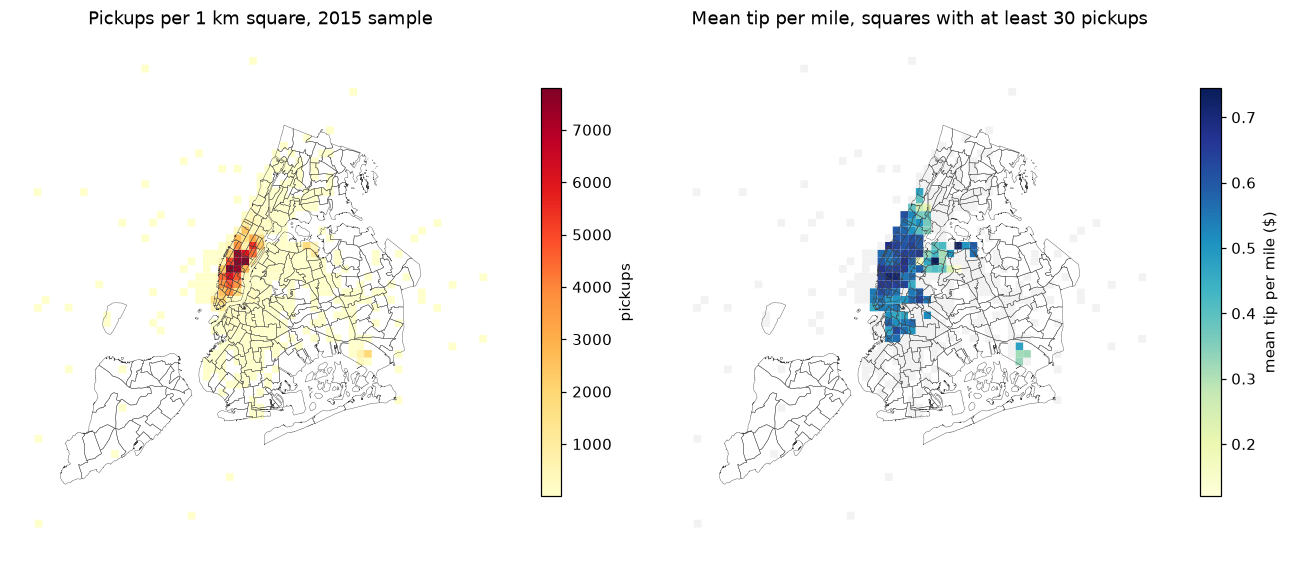

In [5]:
mapped = squares.copy()  # a copy, so the filter below does not change the table
mapped.loc[mapped.pickups < 30, "tip_per_mile"] = None  # thin squares stay blank on the tip map

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))  # count, then tip per mile
squares.plot(  # every square that had a pickup
    "pickups", ax=axes[0], cmap="YlOrRd", legend=True,
    legend_kwds={"label": "pickups", "shrink": 0.7},
)
zones.boundary.plot(ax=axes[0], color="0.25", linewidth=0.25)  # zone outlines
axes[0].set_axis_off()
axes[0].set_title("Pickups per 1 km square, 2015 sample")

mapped.plot(  # tip per mile where the square has enough trips
    "tip_per_mile", ax=axes[1], cmap="YlGnBu", legend=True,
    missing_kwds={"color": "#f2f2f2"},
    legend_kwds={"label": "mean tip per mile ($)", "shrink": 0.7},
)
zones.boundary.plot(ax=axes[1], color="0.25", linewidth=0.25)  # same outlines
axes[1].set_axis_off()
axes[1].set_title("Mean tip per mile, squares with at least 30 pickups")
fig.tight_layout()

The 2015 sample puts 143,744 pickups into 403 squares. The busiest square has 7,795 pickups and sits in Midtown, near Herald Square and Penn Station (about 40.75 N, 73.99 W). The dense squares follow Manhattan south of Central Park. Mean tip per mile is highest in that same Midtown core, where a short trip still carries a tip of a dollar or two. Squares toward the airports sit lower on this scale, because the distance in the denominator is much longer.

## Zones and boroughs

Hsu ranked zones by pickups and by drop-offs, then totaled the boroughs. January 2023 joins `PULocationID` and `DOLocationID` to `taxi_zone_lookup.parquet`. TLC zones 264 and 265 are stored with borough `Unknown` (the zone name is `NV` or blank) when the zone was not recorded. Those rows stay out of the ranking. The choropleth uses the TLC polygons, so a zone id that has no polygon does not appear on the map.

In [6]:
top_pu = db.query(f"""
SELECT z.Zone AS zone, z.Borough AS borough, count(*) AS pickups
FROM read_parquet('{TRIPS.as_posix()}') AS t
JOIN read_parquet('{ZLOOKUP.as_posix()}') AS z
  ON z.LocationID = t.PULocationID
WHERE z.Borough <> 'Unknown'          -- drop TLC zones 264 and 265
GROUP BY z.Zone, z.Borough
ORDER BY pickups DESC
LIMIT 8
""")
top_do = db.query(f"""
SELECT z.Zone AS zone, z.Borough AS borough, count(*) AS dropoffs
FROM read_parquet('{TRIPS.as_posix()}') AS t
JOIN read_parquet('{ZLOOKUP.as_posix()}') AS z
  ON z.LocationID = t.DOLocationID
WHERE z.Borough <> 'Unknown'
GROUP BY z.Zone, z.Borough
ORDER BY dropoffs DESC
LIMIT 8
""")
boroughs = db.query(f"""
SELECT z.Borough AS borough,
       count(*) AS pickups
FROM read_parquet('{TRIPS.as_posix()}') AS t
JOIN read_parquet('{ZLOOKUP.as_posix()}') AS z
  ON z.LocationID = t.PULocationID
GROUP BY z.Borough
ORDER BY pickups DESC
""")
print("Most pickups")
print(top_pu.to_string(index=False))
print()
print("Most drop-offs")
print(top_do.to_string(index=False))
print()
print("Pickups by borough")
print(boroughs.to_string(index=False))

Most pickups
                        zone   borough  pickups
                 JFK Airport    Queens   151267
       Upper East Side South Manhattan   143163
       Upper East Side North Manhattan   133674
              Midtown Center Manhattan   130669
Penn Station/Madison Sq West Manhattan   105535
                Midtown East Manhattan   101854
         Lincoln Square East Manhattan    96724
   Times Sq/Theatre District Manhattan    95348

Most drop-offs
                     zone   borough  dropoffs
    Upper East Side North Manhattan    141773
    Upper East Side South Manhattan    128115
           Midtown Center Manhattan    112017
Times Sq/Theatre District Manhattan     86419
              Murray Hill Manhattan     85752
    Upper West Side South Manhattan     85184
      Lincoln Square East Manhattan     85073
          Lenox Hill West Manhattan     84745

Pickups by borough
      borough  pickups
    Manhattan  2616013
       Queens   267638
      Unknown    37813
     Brooklyn

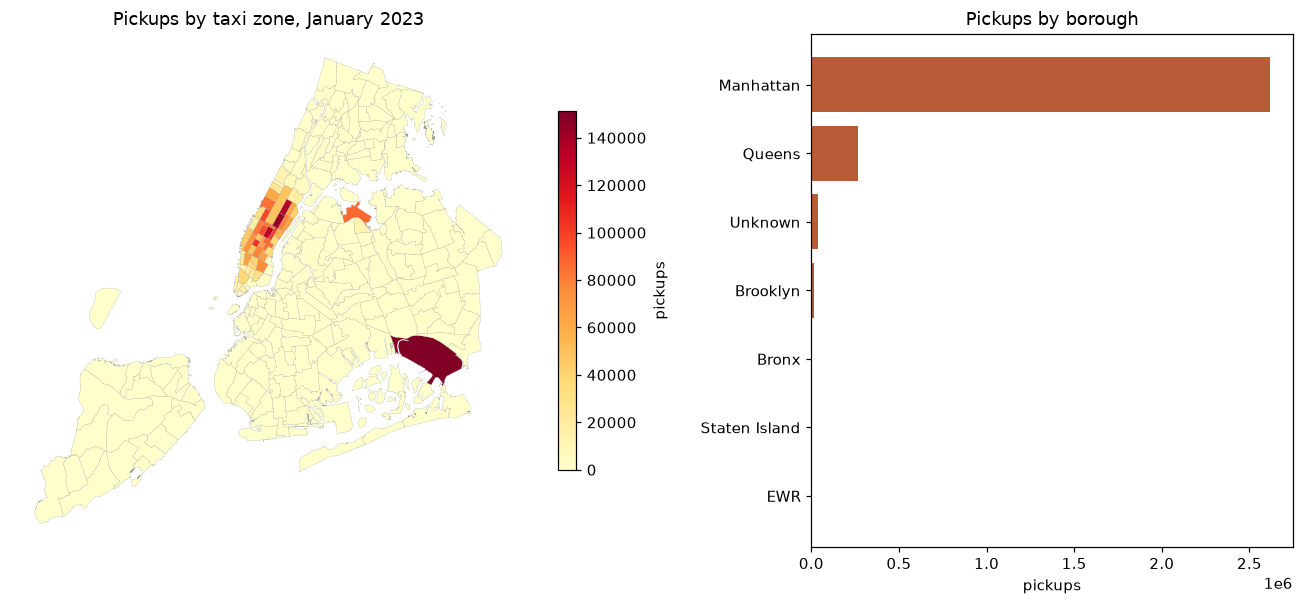

In [7]:
pu = db.query(f"""
SELECT PULocationID AS LocationID, count(*) AS pickups
FROM read_parquet('{TRIPS.as_posix()}')
GROUP BY PULocationID
""")  # one count per zone id
zmap = zones.merge(pu, on="LocationID", how="left")  # counts onto the polygons
zmap["pickups"] = zmap["pickups"].fillna(0)  # a zone with no January pickup

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1.35, 1]})
zmap.plot(  # January 2023 pickups
    "pickups", ax=axes[0], cmap="YlOrRd", legend=True, edgecolor="0.6", linewidth=0.15,
    legend_kwds={"label": "pickups", "shrink": 0.7},
)
axes[0].set_axis_off()
axes[0].set_title("Pickups by taxi zone, January 2023")

order = boroughs.sort_values("pickups")  # smallest borough at the bottom
axes[1].barh(order.borough, order.pickups, color="#b85c38")  # one bar per borough
axes[1].set_xlabel("pickups")
axes[1].set_title("Pickups by borough")
fig.tight_layout()

JFK Airport is the busiest pickup zone in this month (151,267 trips), then Upper East Side South, Upper East Side North, and Midtown Center. Drop-offs concentrate on the Upper East Side and Midtown. Manhattan has 2,616,013 pickups. Staten Island has 217. Hsu's first half of 2017 put Upper East Side South first, with JFK first among zones outside Manhattan. One January is enough to put the airport at the top of the pickup list.

## Peak hours

The pickup timestamp is a column, so the daily pattern is `hour(tpep_pickup_datetime)` and a count. Hsu's first half of 2017 peaked around 18:00-19:00 and was quietest around 05:00.

Busiest hour: 18:00, 207,726 trips
Quietest hour: 04:00, 16,506 trips


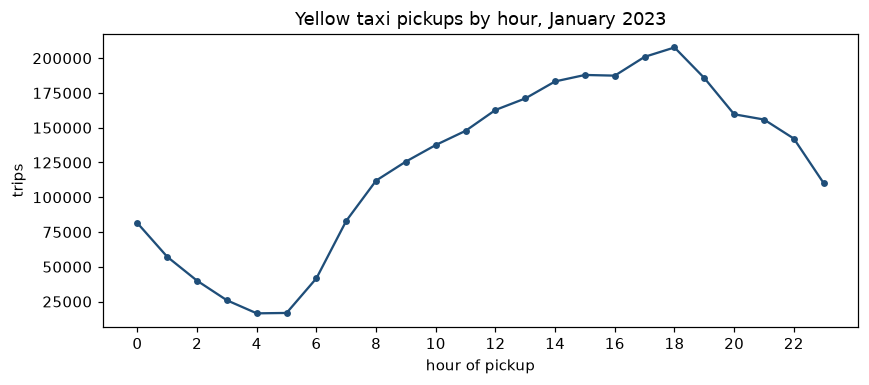

In [8]:
hours = db.query(f"""
SELECT hour(tpep_pickup_datetime) AS hour, count(*) AS trips
FROM read_parquet('{TRIPS.as_posix()}')
GROUP BY hour
ORDER BY hour
""")  # 24 rows, one per hour of the day

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(hours.hour, hours.trips, color="#1f4e79", marker="o", markersize=3.5)  # trips by hour
ax.set_xticks(range(0, 24, 2))  # labels every two hours
ax.set_xlabel("hour of pickup")
ax.set_ylabel("trips")
ax.set_title("Yellow taxi pickups by hour, January 2023")
fig.tight_layout()

peak = hours.loc[hours.trips.idxmax()]  # the busiest hour
quiet = hours.loc[hours.trips.idxmin()]  # the quietest hour
print(f"Busiest hour: {int(peak.hour):02d}:00, {int(peak.trips):,} trips")
print(f"Quietest hour: {int(quiet.hour):02d}:00, {int(quiet.trips):,} trips")

January 2023 is busiest at 18:00 (207,726 trips) and quietest at 04:00 (16,506). The evening peak matches Hsu's longer series. The quiet hour sits one hour earlier than the 05:00 she reported for 2017.

## Short trips and long trips

Hsu split trips at 30 miles, about the distance across the city. The same cut is used here. Trips with `trip_distance` of 0 are left out of the split. The rate codes follow the TLC data dictionary: 1 standard, 2 JFK, 3 Newark, 4 Nassau or Westchester, 5 negotiated. Payment type 1 is a credit card and 2 is cash.

In [9]:
split = db.query(f"""
SELECT
    count(*) FILTER (WHERE trip_distance > 0 AND trip_distance < 30) AS short_trips,
    count(*) FILTER (WHERE trip_distance >= 30) AS long_trips,
    quantile_cont(trip_distance, 0.5) FILTER (WHERE trip_distance > 0) AS median_miles
FROM read_parquet('{TRIPS.as_posix()}')
""")
by_hour = db.query(f"""
SELECT hour(tpep_pickup_datetime) AS hour,
       count(*) FILTER (WHERE trip_distance > 0 AND trip_distance < 30) AS short_trips,
       count(*) FILTER (WHERE trip_distance >= 30) AS long_trips
FROM read_parquet('{TRIPS.as_posix()}')
GROUP BY hour
ORDER BY hour
""")
rates = db.query(f"""
SELECT CASE CAST(RatecodeID AS INTEGER)
           WHEN 1 THEN 'standard'
           WHEN 2 THEN 'JFK'
           WHEN 3 THEN 'Newark'
           WHEN 4 THEN 'Nassau or Westchester'
           WHEN 5 THEN 'negotiated'
           ELSE 'other'
       END AS rate,
       count(*) FILTER (WHERE trip_distance > 0 AND trip_distance < 30) AS short_trips,
       count(*) FILTER (WHERE trip_distance >= 30) AS long_trips
FROM read_parquet('{TRIPS.as_posix()}')
GROUP BY rate
ORDER BY short_trips DESC
""")
pays = db.query(f"""
SELECT CASE payment_type
           WHEN 1 THEN 'credit card'
           WHEN 2 THEN 'cash'
           WHEN 3 THEN 'no charge'
           WHEN 4 THEN 'dispute'
           ELSE 'other'
       END AS payment,
       count(*) FILTER (WHERE trip_distance > 0 AND trip_distance < 30) AS short_trips,
       count(*) FILTER (WHERE trip_distance >= 30) AS long_trips
FROM read_parquet('{TRIPS.as_posix()}')
GROUP BY payment
ORDER BY short_trips DESC
""")

def shares(frame, key):  # percent of each group, so the small long-trip set is readable
    out = frame.copy()
    out["short_pct"] = (100 * out.short_trips / out.short_trips.sum()).round(1)
    out["long_pct"] = (100 * out.long_trips / out.long_trips.sum()).round(1)
    return out[[key, "short_trips", "short_pct", "long_trips", "long_pct"]]

print(
    f"Short trips: {int(split.short_trips.iloc[0]):,}. "
    f"Long trips: {int(split.long_trips.iloc[0]):,}. "
    f"Median distance: {split.median_miles.iloc[0]:.2f} miles."
)
print()
print("Rate code")
print(shares(rates, "rate").to_string(index=False))
print()
print("Payment")
print(shares(pays, "payment").to_string(index=False))

Short trips: 2,938,076. Long trips: 2,317. Median distance: 1.81 miles.

Rate code
                 rate  short_trips  short_pct  long_trips  long_pct
             standard      2815954       95.8         387      16.7
                  JFK       106991        3.6         158       6.8
               Newark         7250        0.2         513      22.1
           negotiated         4369        0.1         599      25.9
Nassau or Westchester         3512        0.1         660      28.5

Payment
    payment  short_trips  short_pct  long_trips  long_pct
credit card      2345173       79.8        1737      75.0
       cash       504540       17.2         522      22.5
      other        64106        2.2          10       0.4
    dispute        15686        0.5          37       1.6
  no charge         8571        0.3          11       0.5


In [10]:
short_routes = db.query(f"""
SELECT pz.Zone AS pickup, dz.Zone AS dropoff, count(*) AS trips
FROM read_parquet('{TRIPS.as_posix()}') AS t
JOIN read_parquet('{ZLOOKUP.as_posix()}') AS pz ON pz.LocationID = t.PULocationID
JOIN read_parquet('{ZLOOKUP.as_posix()}') AS dz ON dz.LocationID = t.DOLocationID
WHERE t.trip_distance > 0 AND t.trip_distance < 30
  AND pz.Borough <> 'Unknown' AND dz.Borough <> 'Unknown'
GROUP BY pickup, dropoff
ORDER BY trips DESC
LIMIT 5
""")
long_routes = db.query(f"""
SELECT CASE WHEN pz.Borough = 'Unknown' THEN 'Unknown zone' ELSE pz.Zone END AS pickup,
       CASE WHEN dz.Borough = 'Unknown' THEN 'Unknown zone' ELSE dz.Zone END AS dropoff,
       count(*) AS trips
FROM read_parquet('{TRIPS.as_posix()}') AS t
JOIN read_parquet('{ZLOOKUP.as_posix()}') AS pz ON pz.LocationID = t.PULocationID
JOIN read_parquet('{ZLOOKUP.as_posix()}') AS dz ON dz.LocationID = t.DOLocationID
WHERE t.trip_distance >= 30
GROUP BY pickup, dropoff
ORDER BY trips DESC
LIMIT 5
""")
print("Busiest short routes")
print(short_routes.to_string(index=False))
print()
print("Busiest long routes")
print(long_routes.to_string(index=False))

Busiest short routes
               pickup               dropoff  trips
Upper East Side South Upper East Side North  21669
Upper East Side North Upper East Side South  18442
Upper East Side North Upper East Side North  13925
Upper East Side South Upper East Side South  13599
Upper East Side South        Midtown Center   9118

Busiest long routes
           pickup        dropoff  trips
      JFK Airport   Unknown zone   1014
      JFK Airport Newark Airport    374
LaGuardia Airport   Unknown zone    178
     Unknown zone   Unknown zone     56
LaGuardia Airport Newark Airport     37


Long trips peak at 16:00


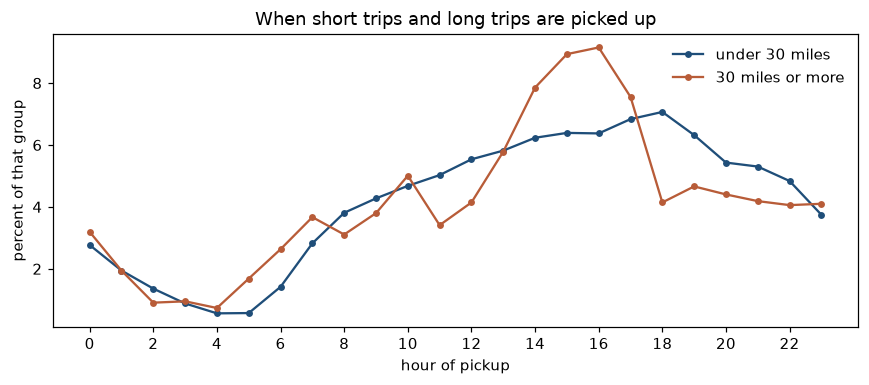

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
# Share of each group, so 2,317 long trips can be read against 2.9 million short ones.
ax.plot(by_hour.hour, 100 * by_hour.short_trips / by_hour.short_trips.sum(),
        color="#1f4e79", marker="o", markersize=3.5, label="under 30 miles")
ax.plot(by_hour.hour, 100 * by_hour.long_trips / by_hour.long_trips.sum(),
        color="#b85c38", marker="o", markersize=3.5, label="30 miles or more")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of pickup")
ax.set_ylabel("percent of that group")
ax.set_title("When short trips and long trips are picked up")
ax.legend(frameon=False)
fig.tight_layout()
print(
    "Long trips peak at "
    f"{int(by_hour.loc[by_hour.long_trips.idxmax(), 'hour']):02d}:00"
)

Almost every January trip is under 30 miles: 2,938,076 short trips against 2,317 long ones, and the median distance is 1.81 miles. The busiest short route is Upper East Side South to Upper East Side North. The busiest long route is JFK Airport to an unrecorded drop-off zone, then JFK Airport to Newark Airport. Long trips peak at 16:00, in the afternoon, while short trips follow the 18:00 citywide peak.

The rate codes separate the two groups more clearly than the payment type does. About 96% of short trips use the standard rate. About 17% of long trips do. The rest of the long trips are JFK, Newark, Nassau or Westchester, or a negotiated fare. Both groups pay mostly by credit card (about 80% of short trips and about 75% of long trips). Hsu's 2017 tables showed the same airport pattern for long trips, with a credit-card share slightly higher on the long trips than on the short ones.

## Summary and exercises

**Main points**

- A 1 km square grid is a `GROUP BY` on coordinates projected to metres. PostGIS writes the same grid with `ST_SquareGrid`.
- The January 2023 zone id joins to the TLC zone table. The polygons turn that count into a map. JFK Airport leads pickups in this month, and Manhattan dominates the boroughs.
- `hour(tpep_pickup_datetime)` is enough for the daily cycle: 18:00 is the peak and 04:00 is the trough.
- A 30 mile cut leaves a few thousand long trips. They run between airports in the afternoon, and they use the special rate codes.

**Functions used:** DuckDB `ST_Point`, `ST_Transform`, `ST_X`, `ST_MakeEnvelope`, `read_parquet`, `hour`, `quantile_cont`; PostGIS `ST_SquareGrid` (the same grid, shown above); `pdb.connect`, `db.load`, `db.query` (`geolattice.geolatticedb`).

**Exercises**

1. Repeat the borough table for drop-offs. Which borough gains the most trips between pickup and drop-off?
2. Rebuild the squares at 500 m (`floor(ST_X(g) / 500)`). Does the busiest cell stay in Midtown?
3. Move the long-trip cut from 30 miles to 10 miles and list the new top origin-destination pair.
4. Esri's sample symbolized each square by maximum tip divided by maximum distance. Add those two aggregates to the square query and compare that map with the mean tip per mile.

In [12]:
db.close()  # close the DuckDB file